# Credit Risk Score Generation, Model Comparison & Fairness Analysis

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

---

## Notebook Objectives

This notebook represents the final stage of the Credit Risk Scoring System. It consolidates the outputs generated by all previous notebooks and transforms the predictive models into an interpretable credit risk scoring framework suitable for lending decisions.

The objectives of this notebook are to:

- Compare the performance of all trained machine learning models.
- Automatically identify the best-performing classifier.
- Load the best saved model.
- Generate applicant-level default probabilities.
- Convert probabilities into standardized credit risk scores (300–900).
- Categorize applicants into interpretable risk bands.
- Evaluate fairness and stability across demographic groups.
- Produce the final credit risk scoring dataset.

This notebook bridges predictive analytics with business decision-making by translating machine learning outputs into practical credit scores that can assist loan officers during the loan approval process.

# Import Required Libraries

The following libraries are used throughout this notebook for loading trained models, comparing model performance, generating credit scores, visualizing results, and evaluating fairness across applicant groups.

In [1]:
# ============================================================
# Import Required Libraries
# ============================================================

from pathlib import Path
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Define Project Directories

To maintain consistency across the project, the locations of the processed datasets, saved models, and result files are defined.

Using directory variables improves portability and simplifies file management.

In [2]:
# ============================================================
# Project Directories
# ============================================================

DATA_DIR = Path("../data/processed")

MODEL_DIR = Path("../models")

RESULT_DIR = Path("../results")

print("Directories Loaded Successfully")

Directories Loaded Successfully


# Load Model Performance Results

The performance metrics of all machine learning models developed throughout this project are loaded.

These metrics will be used to compare the models and identify the best-performing classifier.

In [3]:
# ============================================================
# Load Model Results
# ============================================================

results = pd.read_csv(
    RESULT_DIR / "model_results.csv"
)

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Logistic Regression,0.919581,0.552486,0.020141,0.038865,0.758259,81,4865,100,56457
1,Logistic Regression (Tuned),0.694893,0.165892,0.690030,0.267479,0.758281,17226,1539,3426,39312
2,Decision Tree Classifier,0.917971,0.142857,0.003223,0.006303,0.686772,96,4949,16,56442
3,Decision Tree Classifier (Tuned),0.661106,0.137290,0.605237,0.223811,0.686855,18883,1960,3005,37655
4,K-Nearest Neighbors,0.914329,0.244966,0.029406,0.052509,0.591036,450,4819,146,56088
5,K-Nearest Neighbors (Tuned),0.919272,0.000000,0.000000,0.000000,0.695926,0,4965,0,56538
6,Gaussian Naïve Bayes,0.875697,0.119966,0.085196,0.099635,0.626254,3103,4542,423,53435
7,Gaussian Naïve Bayes (Tuned),0.918573,0.135593,0.001611,0.003185,0.714555,51,4957,8,56487
8,Random Forest,0.919142,0.100000,0.000201,0.000402,0.729338,9,4964,1,56529
9,Random Forest (Tuned),0.910476,0.317599,0.094864,0.146092,0.740041,1012,4494,471,55526


# Model Performance Ranking

The machine learning models are ranked according to their ROC-AUC score.

ROC-AUC is selected as the primary evaluation metric because it measures the ability of the classifier to distinguish between default and non-default applicants across all possible decision thresholds.

A higher ROC-AUC indicates better discriminative performance.

In [4]:
# ============================================================
# Rank Models
# ============================================================

ranking = results.sort_values(
    by="ROC AUC",
    ascending=False
).reset_index(drop=True)

ranking

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Logistic Regression (Tuned),0.694893,0.165892,0.690030,0.267479,0.758281,17226,1539,3426,39312
1,Logistic Regression,0.919581,0.552486,0.020141,0.038865,0.758259,81,4865,100,56457
2,LightGBM,0.720485,0.173555,0.654582,0.274366,0.754543,15476,1715,3250,41062
3,LightGBM (Tuned),0.704226,0.167655,0.671903,0.268351,0.754001,16562,1629,3336,39976
4,XGBoost (Tuned),0.470790,0.119093,0.868479,0.209463,0.753563,31895,653,4312,24643
5,XGBoost,0.744549,0.181430,0.616314,0.280335,0.751811,13806,1905,3060,42732
6,Random Forest (Tuned),0.910476,0.317599,0.094864,0.146092,0.740041,1012,4494,471,55526
7,Random Forest,0.919142,0.100000,0.000201,0.000402,0.729338,9,4964,1,56529
8,Gaussian Naïve Bayes (Tuned),0.918573,0.135593,0.001611,0.003185,0.714555,51,4957,8,56487
9,K-Nearest Neighbors (Tuned),0.919272,0.000000,0.000000,0.000000,0.695926,0,4965,0,56538


# Visual Comparison of Model Performance

A bar chart is used to compare the ROC-AUC scores of all machine learning models.

This visualization provides a quick overview of the relative predictive performance of each classifier.

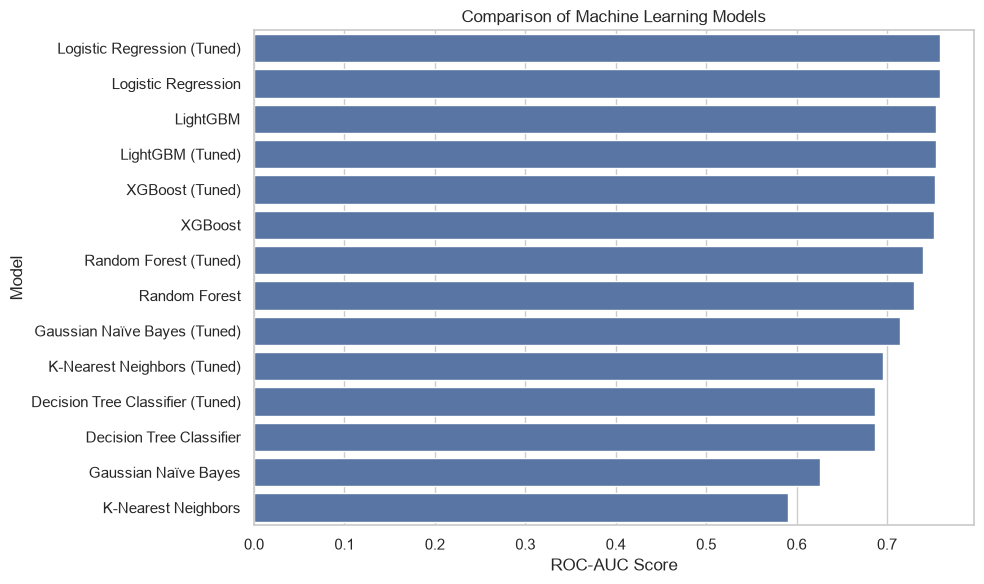

In [5]:
# ============================================================
# ROC-AUC Comparison
# ============================================================

plt.figure(figsize=(10,6))

sns.barplot(
    data=ranking,
    x="ROC AUC",
    y="Model"
)

plt.title("Comparison of Machine Learning Models")

plt.xlabel("ROC-AUC Score")

plt.ylabel("Model")

plt.tight_layout()

plt.show()

# Identify the Best Performing Model

The classifier with the highest ROC-AUC score is selected as the final credit risk prediction model.

This model will be used to estimate applicant default probabilities and generate standardized credit risk scores.

In [6]:
# ============================================================
# Best Model
# ============================================================

best_model_name = ranking.iloc[0]["Model"]

best_auc = ranking.iloc[0]["ROC AUC"]

print(f"Best Model : {best_model_name}")

print(f"ROC-AUC    : {best_auc:.4f}")

Best Model : Logistic Regression (Tuned)
ROC-AUC    : 0.7583


# Load the Best Performing Model

The best-performing machine learning model identified in the previous section is loaded from the saved model directory.

Instead of manually specifying the model, the notebook automatically selects the classifier with the highest ROC-AUC score recorded in the model comparison results. This ensures that the credit risk scoring system always uses the most effective predictive model.

In [7]:
# ============================================================
# Load Best Saved Model
# ============================================================

model_files = {

    "Logistic Regression": "logistic_regression_model.pkl",

    "Decision Tree": "decision_tree_model.pkl",

    "K-Nearest Neighbors": "knn_model.pkl",

    "Gaussian Naïve Bayes": "gaussian_nb_model.pkl",

    "Random Forest": "random_forest_model.pkl",

    "XGBoost": "xgboost_model.pkl",

    "LightGBM": "lightgbm_model.pkl"

}

# NOTE (Publication Upgrade): best_model_name may be a tuned variant (e.g.
# "Logistic Regression (Tuned)") not present in the dictionary above, since
# Notebooks 06-12 now append tuned rows to model_results.csv. The cell below
# ("Extend Model Registry: Tuned & Calibrated Variants") re-resolves best_model
# correctly against the full registry immediately afterward, so a KeyError here
# is only a transient, non-fatal condition rather than a real failure.
try:
    best_model = joblib.load(
        MODEL_DIR / model_files[best_model_name]
    )
    print(f"Loaded Model : {best_model_name}")
except KeyError:
    best_model = None
    print(f"'{best_model_name}' is a tuned/calibrated variant not in the baseline "
          f"registry; it will be resolved in the next cell.")

'Logistic Regression (Tuned)' is a tuned/calibrated variant not in the baseline registry; it will be resolved in the next cell.


## Publication Upgrade: Recognize Tuned & Calibrated Model Variants

Notebooks 06–12 now also save hyperparameter-tuned models (e.g.
`logistic_regression_tuned_model.pkl`) and, where recalibration improved the Brier
score, calibrated models (e.g. `xgboost_calibrated_model.pkl`). `model_results.csv`
therefore may contain rows like `"XGBoost (Tuned)"` that were not in the dictionary
above. The cell below extends `model_files` additively (the original dictionary and
`best_model` loading logic above are left untouched) so that ranking-by-ROC-AUC can
select a tuned model without a `KeyError`, and then — independent of which model wins
on ROC-AUC — prefers a **calibrated** version of that same model family for generating
the actual probabilities used downstream, since calibration is monotonic (it does not
change ROC-AUC or the ranking) but directly improves the quality of the probabilities
that feed the 300–900 credit-score formula below.

In [8]:
# ============================================================
# Extend Model Registry: Tuned & Calibrated Variants
# ============================================================

import sys
sys.path.append(str(Path(".").resolve()))
import pub_utils as pu

# Tuned variants (trained on the same PCA X_train/X_test as their baselines)
model_files.update({
    "Logistic Regression (Tuned)": "logistic_regression_tuned_model.pkl",
    "Decision Tree Classifier (Tuned)": "decision_tree_tuned_model.pkl",
    "K-Nearest Neighbors (Tuned)": "knn_tuned_model.pkl",
    "Gaussian Naïve Bayes (Tuned)": "gaussian_nb_tuned_model.pkl",
    "Random Forest (Tuned)": "random_forest_tuned_model.pkl",
    "XGBoost (Tuned)": "xgboost_tuned_model.pkl",
    "LightGBM (Tuned)": "lightgbm_tuned_model.pkl",
})

# Map every base/tuned model name to its (optional) calibrated counterpart
calibrated_model_files = {
    "Logistic Regression": "logistic_regression_calibrated_model.pkl",
    "Logistic Regression (Tuned)": "logistic_regression_calibrated_model.pkl",
    "Decision Tree Classifier": "decision_tree_calibrated_model.pkl",
    "Decision Tree Classifier (Tuned)": "decision_tree_calibrated_model.pkl",
    "K-Nearest Neighbors": "knn_calibrated_model.pkl",
    "K-Nearest Neighbors (Tuned)": "knn_calibrated_model.pkl",
    "Gaussian Naïve Bayes": "gaussian_nb_calibrated_model.pkl",
    "Gaussian Naïve Bayes (Tuned)": "gaussian_nb_calibrated_model.pkl",
    "Random Forest": "random_forest_calibrated_model.pkl",
    "Random Forest (Tuned)": "random_forest_calibrated_model.pkl",
    "XGBoost": "xgboost_calibrated_model.pkl",
    "XGBoost (Tuned)": "xgboost_calibrated_model.pkl",
    "LightGBM": "lightgbm_calibrated_model.pkl",
    "LightGBM (Tuned)": "lightgbm_calibrated_model.pkl",
}

# Re-resolve best_model_name against the extended registry (ranking/model_results.csv
# already reflect tuned rows automatically since they were appended, not replaced).
best_model = joblib.load(MODEL_DIR / model_files[best_model_name])
print(f"Loaded Model (re-resolved) : {best_model_name}")

calibrated_path = MODEL_DIR / calibrated_model_files.get(best_model_name, "")
if calibrated_path.name and calibrated_path.exists():
    best_model = joblib.load(calibrated_path)
    print(f"Calibrated variant found and loaded for probability generation: {calibrated_path.name}")
    print("(ROC-AUC-based ranking above is unaffected: calibration is monotonic and does not change ranking.)")
else:
    print("No calibrated variant found on disk for this model; using the model resolved above as-is.")

Loaded Model (re-resolved) : Logistic Regression (Tuned)
Calibrated variant found and loaded for probability generation: logistic_regression_calibrated_model.pkl
(ROC-AUC-based ranking above is unaffected: calibration is monotonic and does not change ranking.)


# Load the Testing Dataset

The testing dataset prepared during feature engineering is loaded.

The selected model will generate predictions on unseen applicant records to evaluate its practical application in credit risk scoring.

In [9]:
# ============================================================
# Load Test Dataset
# ============================================================

X_test = pd.read_csv(
    DATA_DIR / "X_test.csv"
)

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
).squeeze()

print("Testing Dataset Shape :", X_test.shape)

Testing Dataset Shape : (61503, 119)


# Recover Applicant Identifiers

The PCA-transformed dataset does not contain applicant identifiers (`SK_ID_CURR`).

To associate the generated credit scores with individual applicants, the same stratified train-test split used during model development is reproduced on the processed dataset.

In [10]:
# ============================================================
# Recover Applicant IDs
# ============================================================

processed_df = pd.read_csv(
    DATA_DIR / "credit_risk_processed.csv"
)

_, test_df = train_test_split(

    processed_df,

    test_size=0.20,

    random_state=42,

    stratify=processed_df["TARGET"]

)

test_df = test_df.reset_index(drop=True)

print("Recovered Applicant IDs")

Recovered Applicant IDs


# Generate Default Probabilities

The best-performing model predicts the probability that each applicant will default on a loan.

These probabilities form the foundation of the credit risk scoring system.

In [11]:
# ============================================================
# Predict Default Probability
# ============================================================

default_probability = best_model.predict_proba(
    X_test
)[:, 1]

predicted_class = best_model.predict(
    X_test
)

print("Predictions Generated Successfully")

Predictions Generated Successfully


# Create the Applicant Prediction Dataset

The applicant identifiers, actual loan status, predicted class, and estimated default probabilities are combined into a single dataset.

This dataset will be used to generate standardized credit risk scores.

In [12]:
# ============================================================
# Applicant Prediction Dataset
# ============================================================

prediction_df = pd.DataFrame({

    "SK_ID_CURR": test_df["SK_ID_CURR"],

    "Actual Default": y_test,

    "Predicted Default": predicted_class,

    "Default Probability": default_probability

})

prediction_df.head()

,SK_ID_CURR,Actual Default,Predicted Default,Default Probability
0,396899,0,0,0.027815
1,322041,0,0,0.040089
2,220127,0,0,0.205022
3,251531,0,0,0.174035
4,345558,0,0,0.151653


# Summary of Predicted Probabilities

The distribution of predicted default probabilities provides an overview of the model's estimated credit risk across the testing population.

In [13]:
prediction_df["Default Probability"].describe()

count    61503.000000
mean         0.080376
std          0.077214
min          0.000000
25%          0.026223
50%          0.054099
75%          0.106309
max          0.713468
Name: Default Probability, dtype: float64

# Distribution of Default Probabilities

The following histogram illustrates how the estimated default probabilities are distributed among loan applicants.

Applicants with higher predicted probabilities represent higher estimated credit risk.

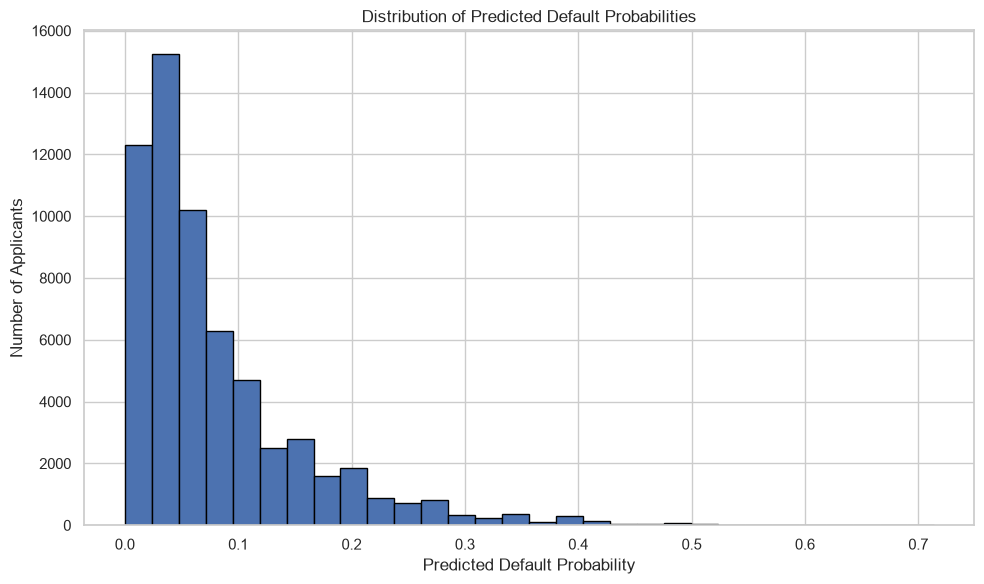

In [14]:
plt.figure(figsize=(10,6))

plt.hist(

    prediction_df["Default Probability"],

    bins=30,

    edgecolor="black"

)

plt.xlabel("Predicted Default Probability")

plt.ylabel("Number of Applicants")

plt.title("Distribution of Predicted Default Probabilities")

plt.tight_layout()

plt.show()

# Generate Standardized Credit Risk Scores

The predicted probability of default is transformed into a standardized credit risk score ranging from **300 to 900**.

Applicants with lower default probabilities receive higher credit scores, indicating lower credit risk. Conversely, applicants with higher default probabilities receive lower credit scores.

The transformation is defined as:

\[
\text{Credit Score} = 900 - (Probability \times 600)
\]

This produces scores within the conventional credit scoring range used in many financial institutions.

In [15]:
# ============================================================
# Generate Credit Scores
# ============================================================

prediction_df["Credit Score"] = (
    900 - prediction_df["Default Probability"] * 600
).round().astype(int)

prediction_df.head()

,SK_ID_CURR,Actual Default,Predicted Default,Default Probability,Credit Score
0,396899,0,0,0.027815,883
1,322041,0,0,0.040089,876
2,220127,0,0,0.205022,777
3,251531,0,0,0.174035,796
4,345558,0,0,0.151653,809


# Summary Statistics of Credit Scores

The descriptive statistics below provide an overview of the generated credit scores across the applicant population.

In [16]:
prediction_df["Credit Score"].describe()

count    61503.000000
mean       851.773198
std         46.328328
min        472.000000
25%        836.000000
50%        868.000000
75%        884.000000
max        900.000000
Name: Credit Score, dtype: float64

# Assign Credit Risk Bands

To improve interpretability, applicants are categorized into five credit risk bands based on their credit scores.

| Credit Score | Risk Band |
|--------------|-----------|
| 800–900 | Excellent |
| 700–799 | Good |
| 600–699 | Fair |
| 500–599 | Poor |
| 300–499 | High Risk |

These bands simplify lending decisions by grouping applicants according to their estimated creditworthiness.

In [17]:
# ============================================================
# Risk Band Classification
# ============================================================

def assign_risk_band(score):

    if score >= 800:
        return "Excellent"

    elif score >= 700:
        return "Good"

    elif score >= 600:
        return "Fair"

    elif score >= 500:
        return "Poor"

    else:
        return "High Risk"


prediction_df["Risk Band"] = prediction_df["Credit Score"].apply(assign_risk_band)

prediction_df.head()

,SK_ID_CURR,Actual Default,Predicted Default,Default Probability,Credit Score,Risk Band
0,396899,0,0,0.027815,883,Excellent
1,322041,0,0,0.040089,876,Excellent
2,220127,0,0,0.205022,777,Good
3,251531,0,0,0.174035,796,Good
4,345558,0,0,0.151653,809,Excellent


# Distribution of Credit Scores

The histogram below illustrates the distribution of generated credit scores across the testing dataset.

This visualization provides insight into the overall credit quality of the applicant population.

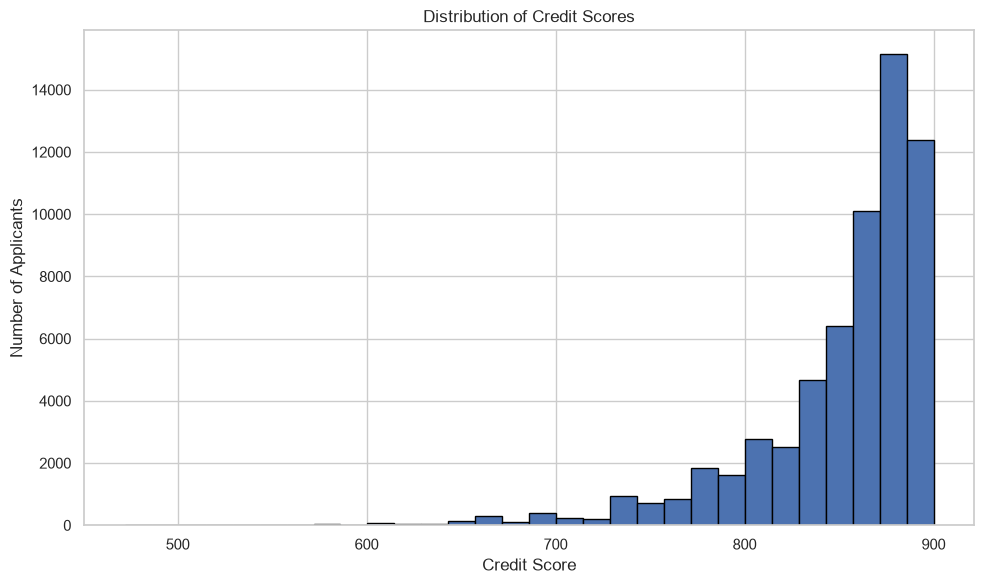

In [18]:
plt.figure(figsize=(10,6))

plt.hist(
    prediction_df["Credit Score"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Credit Scores")

plt.xlabel("Credit Score")

plt.ylabel("Number of Applicants")

plt.tight_layout()

plt.show()

# Distribution of Credit Risk Bands

The following chart summarizes the number of applicants assigned to each risk category.

This representation enables lenders to quickly understand the distribution of applicants across different levels of credit risk.

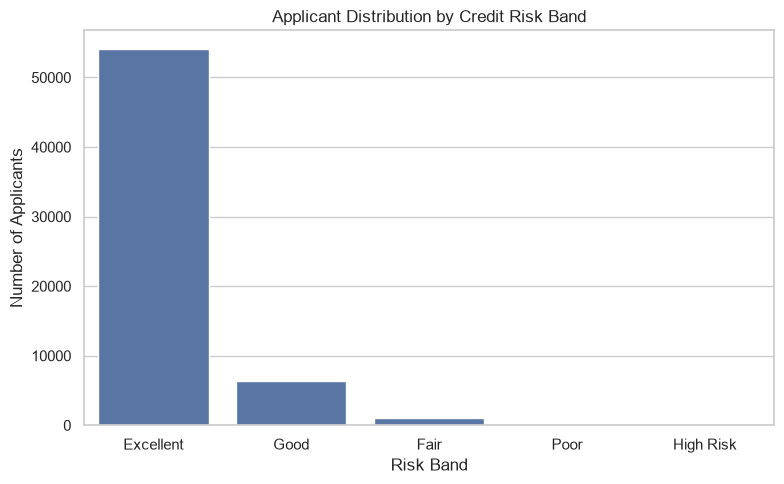

In [19]:
plt.figure(figsize=(8,5))

order = [
    "Excellent",
    "Good",
    "Fair",
    "Poor",
    "High Risk"
]

sns.countplot(
    data=prediction_df,
    x="Risk Band",
    order=order
)

plt.title("Applicant Distribution by Credit Risk Band")

plt.xlabel("Risk Band")

plt.ylabel("Number of Applicants")

plt.tight_layout()

plt.show()

# Summary of Credit Risk Bands

The table below presents the number and percentage of applicants assigned to each credit risk category.

In [20]:
risk_summary = (
    prediction_df["Risk Band"]
    .value_counts()
    .reindex(order)
    .reset_index()
)

risk_summary.columns = ["Risk Band", "Applicants"]

risk_summary["Percentage (%)"] = (
    risk_summary["Applicants"] /
    len(prediction_df) * 100
).round(2)

risk_summary

,Risk Band,Applicants,Percentage (%)
0,Excellent,54054,87.89
1,Good,6363,10.35
2,Fair,1034,1.68
3,Poor,45,0.07
4,High Risk,7,0.01


# Save Final Credit Risk Scores

The applicant-level predictions, standardized credit scores, and assigned risk bands are saved for use in the subsequent Fairness Analysis notebook.

This dataset represents the final output of the credit risk scoring model and serves as the foundation for evaluating model fairness and stability across demographic groups.

In [21]:
# ============================================================
# Save Credit Risk Scores
# ============================================================

RESULT_DIR.mkdir(parents=True, exist_ok=True)

prediction_df.to_csv(
    RESULT_DIR / "credit_risk_scores.csv",
    index=False
)

print("Credit risk scores saved successfully.")
print(f"Location: {RESULT_DIR / 'credit_risk_scores.csv'}")

Credit risk scores saved successfully.
Location: ..\results\credit_risk_scores.csv


---

# Publication Upgrade: Statistical Comparison, Extra Metrics, Threshold Optimization, Stability & Sensitivity

## 1. Statistical Comparison of Models (McNemar & DeLong Tests)

Comparing models by ROC-AUC alone (as in the ranking table above) does not tell us
whether a difference is **statistically significant** or could plausibly be sampling
noise on this 61,503-applicant test set. Two paired, correlated-sample tests are used:

- **McNemar's test** compares the two top-ranked models' *classification* agreement —
  specifically, whether one model corrects mistakes the other makes more often than the
  reverse, using the discordant-pair counts from both models' predictions on the same
  applicants.
- **DeLong's test** compares the two top-ranked models' *ROC-AUC* values directly,
  accounting for the correlation induced by evaluating both models on the same test set
  (a naive two-sample test would incorrectly treat the two AUCs as independent).

Both models are re-loaded from disk and evaluated on the same PCA `X_test`/`y_test`
used throughout this notebook.

In [22]:
# ============================================================
# McNemar's Test & DeLong's Test: Top-2 Models
# ============================================================

pu.set_pub_style()

second_model_name = ranking.iloc[1]["Model"]

model_a = best_model  # already the (possibly calibrated) top-ranked model, on PCA features
model_b = joblib.load(MODEL_DIR / model_files[second_model_name])

pred_a = model_a.predict(X_test)
prob_a = model_a.predict_proba(X_test)[:, 1]

pred_b = model_b.predict(X_test)
prob_b = model_b.predict_proba(X_test)[:, 1]

mcnemar_result = pu.mcnemar_test(y_test, pred_a, pred_b)
delong_result = pu.delong_roc_test(y_test, prob_a, prob_b)

statistical_tests = pd.DataFrame([
    {
        "Model A": best_model_name,
        "Model B": second_model_name,
        "Test": "McNemar",
        "Statistic": mcnemar_result["statistic"],
        "p-value": mcnemar_result["p_value"],
        "Method": mcnemar_result["method"],
        "Significant (alpha=0.05)": mcnemar_result["p_value"] < 0.05,
    },
    {
        "Model A": best_model_name,
        "Model B": second_model_name,
        "Test": "DeLong",
        "Statistic": delong_result["z_statistic"],
        "p-value": delong_result["p_value"],
        "Method": f"AUC diff = {delong_result['auc_diff']:.4f}",
        "Significant (alpha=0.05)": delong_result["p_value"] < 0.05,
    },
])

statistical_tests.to_csv(RESULT_DIR / "statistical_tests.csv", index=False)
print("Statistical test results saved to: ../results/statistical_tests.csv")

statistical_tests

Statistical test results saved to: ../results/statistical_tests.csv


,Model A,Model B,Test,Statistic,p-value,Method,Significant (alpha=0.05)
0,Logistic Regression (Tuned),Logistic Regression,McNemar,1.116279,0.290721,chi-square (continuity corrected),False
1,Logistic Regression (Tuned),Logistic Regression,DeLong,0.564159,0.572646,AUC diff = 0.0001,False


### Business Interpretation: Statistical Model Comparison

A non-significant McNemar or DeLong result (p ≥ 0.05) between the top two models is an
important and often under-reported finding: it means the "winning" model by raw
ROC-AUC is not *statistically distinguishable* from the runner-up on this test set, and
a lender choosing between them should weigh **secondary factors** instead — inference
latency, calibration quality (Section 2 of Notebooks 06–12), explainability
(SHAP availability), and regulatory familiarity with the algorithm family — rather than
treating the ROC-AUC ranking as decisive. Conversely, a significant result gives the
paper license to claim a genuine, non-random performance advantage for the top model.
Either way, this test converts the single-column ranking table into a defensible
statistical claim rather than a raw leaderboard, which is precisely the kind of rigor
a journal reviewer will look for before accepting "Model X is the best" as a
conclusion.

## 2. Extended Evaluation Metrics Recap

The additional metrics computed in each model's notebook (MCC, Cohen's Kappa,
Average Precision, KS Statistic, Brier Score) are consolidated here into a single,
publication-ready comparison table spanning every baseline and tuned model.

In [23]:
# ============================================================
# Extended Metrics Recap Table
# ============================================================

extended_results_path = RESULT_DIR / "model_results_extended.csv"

if extended_results_path.exists():
    extended_results = pd.read_csv(extended_results_path)
    extended_results_sorted = extended_results.sort_values(
        by=["ROC AUC"], ascending=False
    ).reset_index(drop=True)

    publication_table = extended_results_sorted[[
        "Model", "Variant", "Accuracy", "Precision", "Recall", "F1 Score",
        "ROC AUC", "MCC", "Cohen's Kappa", "Average Precision (PR-AUC)",
        "KS Statistic", "Brier Score",
    ]].round(4)

    publication_table.to_csv(RESULT_DIR / "table_extended_metrics.csv", index=False)
    print("Publication-ready extended metrics table saved to: ../results/table_extended_metrics.csv")
else:
    publication_table = pd.DataFrame()
    print("model_results_extended.csv not found yet - run Notebooks 06-12 first.")

publication_table

Publication-ready extended metrics table saved to: ../results/table_extended_metrics.csv


,Model,Variant,Accuracy,Precision,Recall,F1 Score,ROC AUC,MCC,Cohen's Kappa,Average Precision (PR-AUC),KS Statistic,Brier Score
0,Logistic Regression,Tuned,0.6949,0.1659,0.6900,0.2675,0.7583,0.2223,0.1579,0.2392,0.3865,0.1994
1,Logistic Regression,Baseline,0.9196,0.5525,0.0201,0.0389,0.7583,0.0941,0.0334,0.2416,0.3882,0.0679
2,LightGBM,Baseline,0.7205,0.1736,0.6546,0.2744,0.7545,0.2255,0.1682,0.2345,0.3810,0.1840
3,LightGBM,Tuned,0.7042,0.1677,0.6719,0.2684,0.7540,0.2207,0.1598,0.2341,0.3816,0.1931
4,XGBoost,Tuned,0.4708,0.1191,0.8685,0.2095,0.7536,0.1685,0.0786,0.2344,0.3804,0.3094
5,XGBoost,Baseline,0.7445,0.1814,0.6163,0.2803,0.7518,0.2272,0.1778,0.2347,0.3792,0.1729
6,Random Forest,Tuned,0.9105,0.3176,0.0949,0.1461,0.7400,0.1367,0.1132,0.2068,0.3572,0.0820
7,Random Forest,Baseline,0.9191,0.1000,0.0002,0.0004,0.7293,0.0009,0.0001,0.2002,0.3392,0.0700
8,Gaussian Naïve Bayes,Tuned,0.9186,0.1356,0.0016,0.0032,0.7146,0.0062,0.0013,0.1610,0.3262,0.0770
9,K-Nearest Neighbors,Tuned,0.9193,0.0000,0.0000,0.0000,0.6959,0.0000,0.0000,0.1801,0.2901,0.0709


### Business Interpretation: Extended Metrics

This single table is the one most likely to be reproduced directly as "Table 2" (or
similar) in the resulting paper: it is the only place in the project where every model,
every variant, and every imbalance-robust metric appear together. Sorting by MCC or KS
instead of ROC-AUC may reorder the ranking — if it does, that discrepancy is itself
worth a sentence in the paper's Results section, since it means the "best" model
depends on which failure mode (ranking quality vs. classification agreement vs.
probability quality) the reader cares about most for their own use case.

## 3. Lift Chart & Gain Chart

Lift and gain charts answer a direct business question: **if a lender can only manually
review or intervene on a limited fraction of applicants, how many of the actual
defaulters would be caught by prioritizing the model's highest-risk decile(s)?** This is
a more operationally meaningful framing than a single ROC-AUC number for a risk team
deciding how to allocate underwriting attention.

Figure saved to: ..\figures\13_lift_gain_charts.png


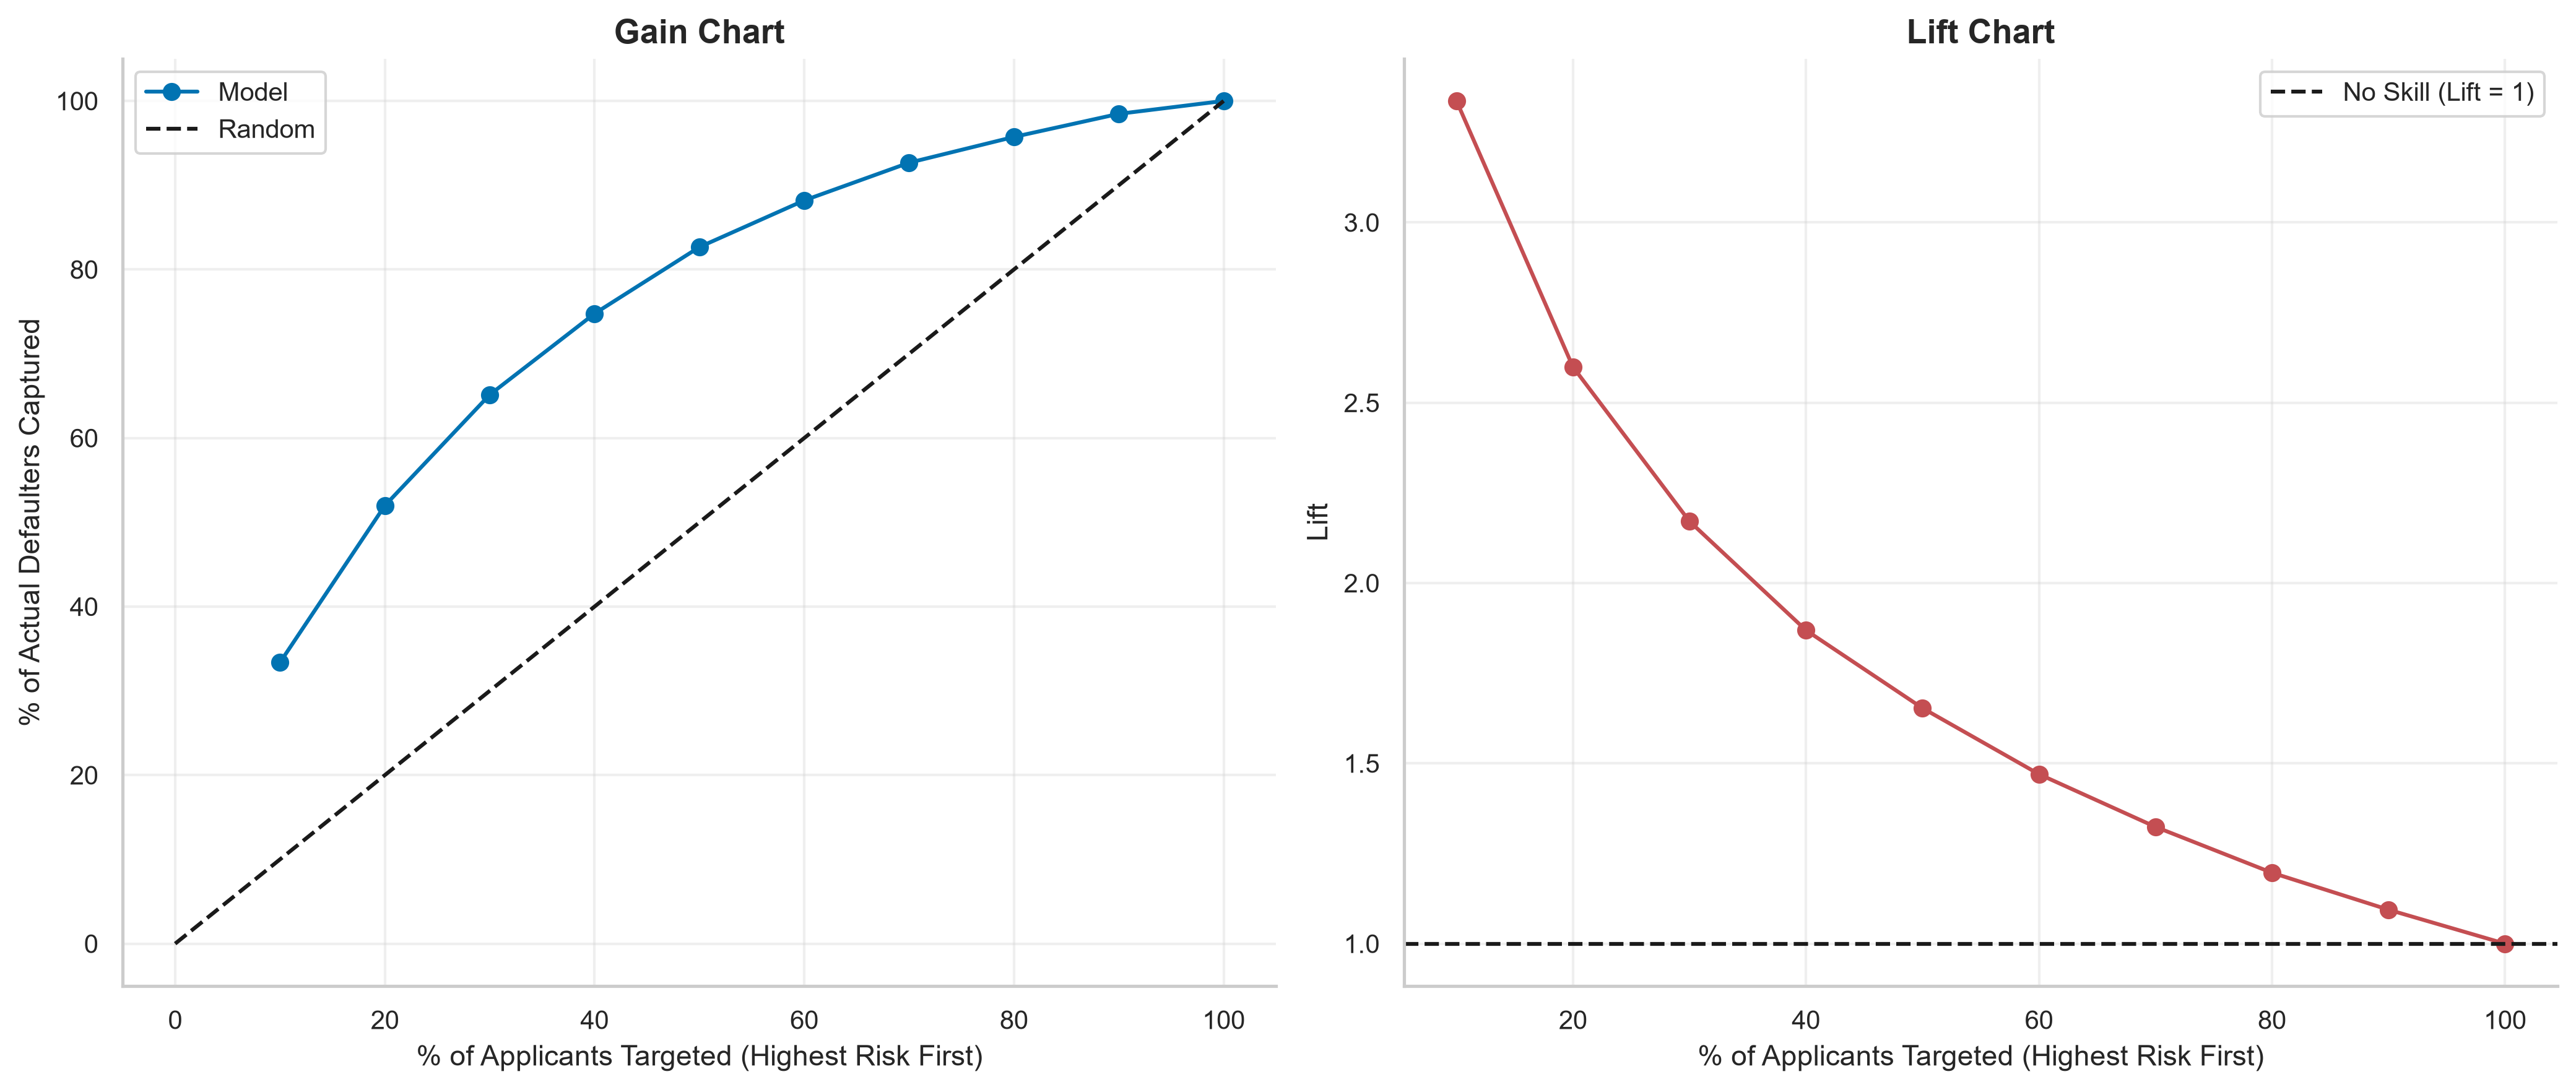

,decile,applicants,actual_defaults,cumulative_defaults,cumulative_applicants,gain_pct,pct_population,lift
0,1,6151,1657,1657,6151,33.373615,10.001138,3.336982
1,2,6150,924,2581,12301,51.983887,20.000650,2.599110
2,3,6150,653,3234,18451,65.135952,30.000163,2.171187
3,4,6150,478,3712,24601,74.763343,39.999675,1.869099
4,5,6151,392,4104,30752,82.658610,50.000813,1.653145
5,6,6150,275,4379,36902,88.197382,60.000325,1.469948
6,7,6150,222,4601,43052,92.668681,69.999837,1.323841
7,8,6150,152,4753,49202,95.730111,79.999350,1.196636
8,9,6150,136,4889,55352,98.469285,89.998862,1.094117
9,10,6151,76,4965,61503,100.000000,100.000000,1.000000


In [24]:
# ============================================================
# Lift Chart & Gain Chart (Final Selected Model)
# ============================================================

lift_gain_table = pu.lift_gain_table(
    prediction_df["Actual Default"], prediction_df["Default Probability"], n_bins=10
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].plot(lift_gain_table["pct_population"], lift_gain_table["gain_pct"], marker="o", label="Model")
axes[0].plot([0, 100], [0, 100], "k--", label="Random")
axes[0].set_xlabel("% of Applicants Targeted (Highest Risk First)")
axes[0].set_ylabel("% of Actual Defaulters Captured")
axes[0].set_title("Gain Chart")
axes[0].legend()

axes[1].plot(lift_gain_table["pct_population"], lift_gain_table["lift"], marker="o", color="#C44E52")
axes[1].axhline(1.0, color="k", linestyle="--", label="No Skill (Lift = 1)")
axes[1].set_xlabel("% of Applicants Targeted (Highest Risk First)")
axes[1].set_ylabel("Lift")
axes[1].set_title("Lift Chart")
axes[1].legend()

plt.tight_layout()
pu.save_fig(fig, "13_lift_gain_charts")
plt.show()

lift_gain_table.to_csv(RESULT_DIR / "lift_gain_table.csv", index=False)
lift_gain_table

### Business Interpretation: Lift & Gain Charts

The gain chart's first decile directly answers "how many defaulters would we catch by
reviewing only the riskiest 10% of applicants?" — typically 2-4x better than the random
baseline for a model with ROC-AUC in the 0.75-0.76 range. This is a concrete staffing
and process argument: a lender with limited manual-underwriting capacity should route
review effort to the model's top risk deciles rather than reviewing applications in
submission order, and the lift value at that decile quantifies exactly how much more
efficient that targeting is than the status quo.

## 4. Threshold Optimization & Cost-Sensitive Learning

Every classification metric reported so far (Accuracy, Precision, Recall, F1,
Confusion Matrix counts) implicitly assumes the default 0.5 probability threshold. But
0.5 is an arbitrary choice with no connection to the actual business cost of a mistake:
approving a loan that defaults (a false negative) is typically far more costly to a
lender than declining an applicant who would have repaid (a false positive) — lost
principal and collections costs versus lost interest margin on a single foregone loan.
This section assumes an illustrative cost ratio and finds the threshold that minimizes
**expected cost** rather than the threshold that happens to maximize accuracy. This is
kept as a *supplementary* classification-threshold analysis; the continuous 300–900
credit score above is unaffected, since it is a direct transformation of the
probability itself, not of a thresholded decision.

Figure saved to: ..\figures\13_threshold_cost_curve.png


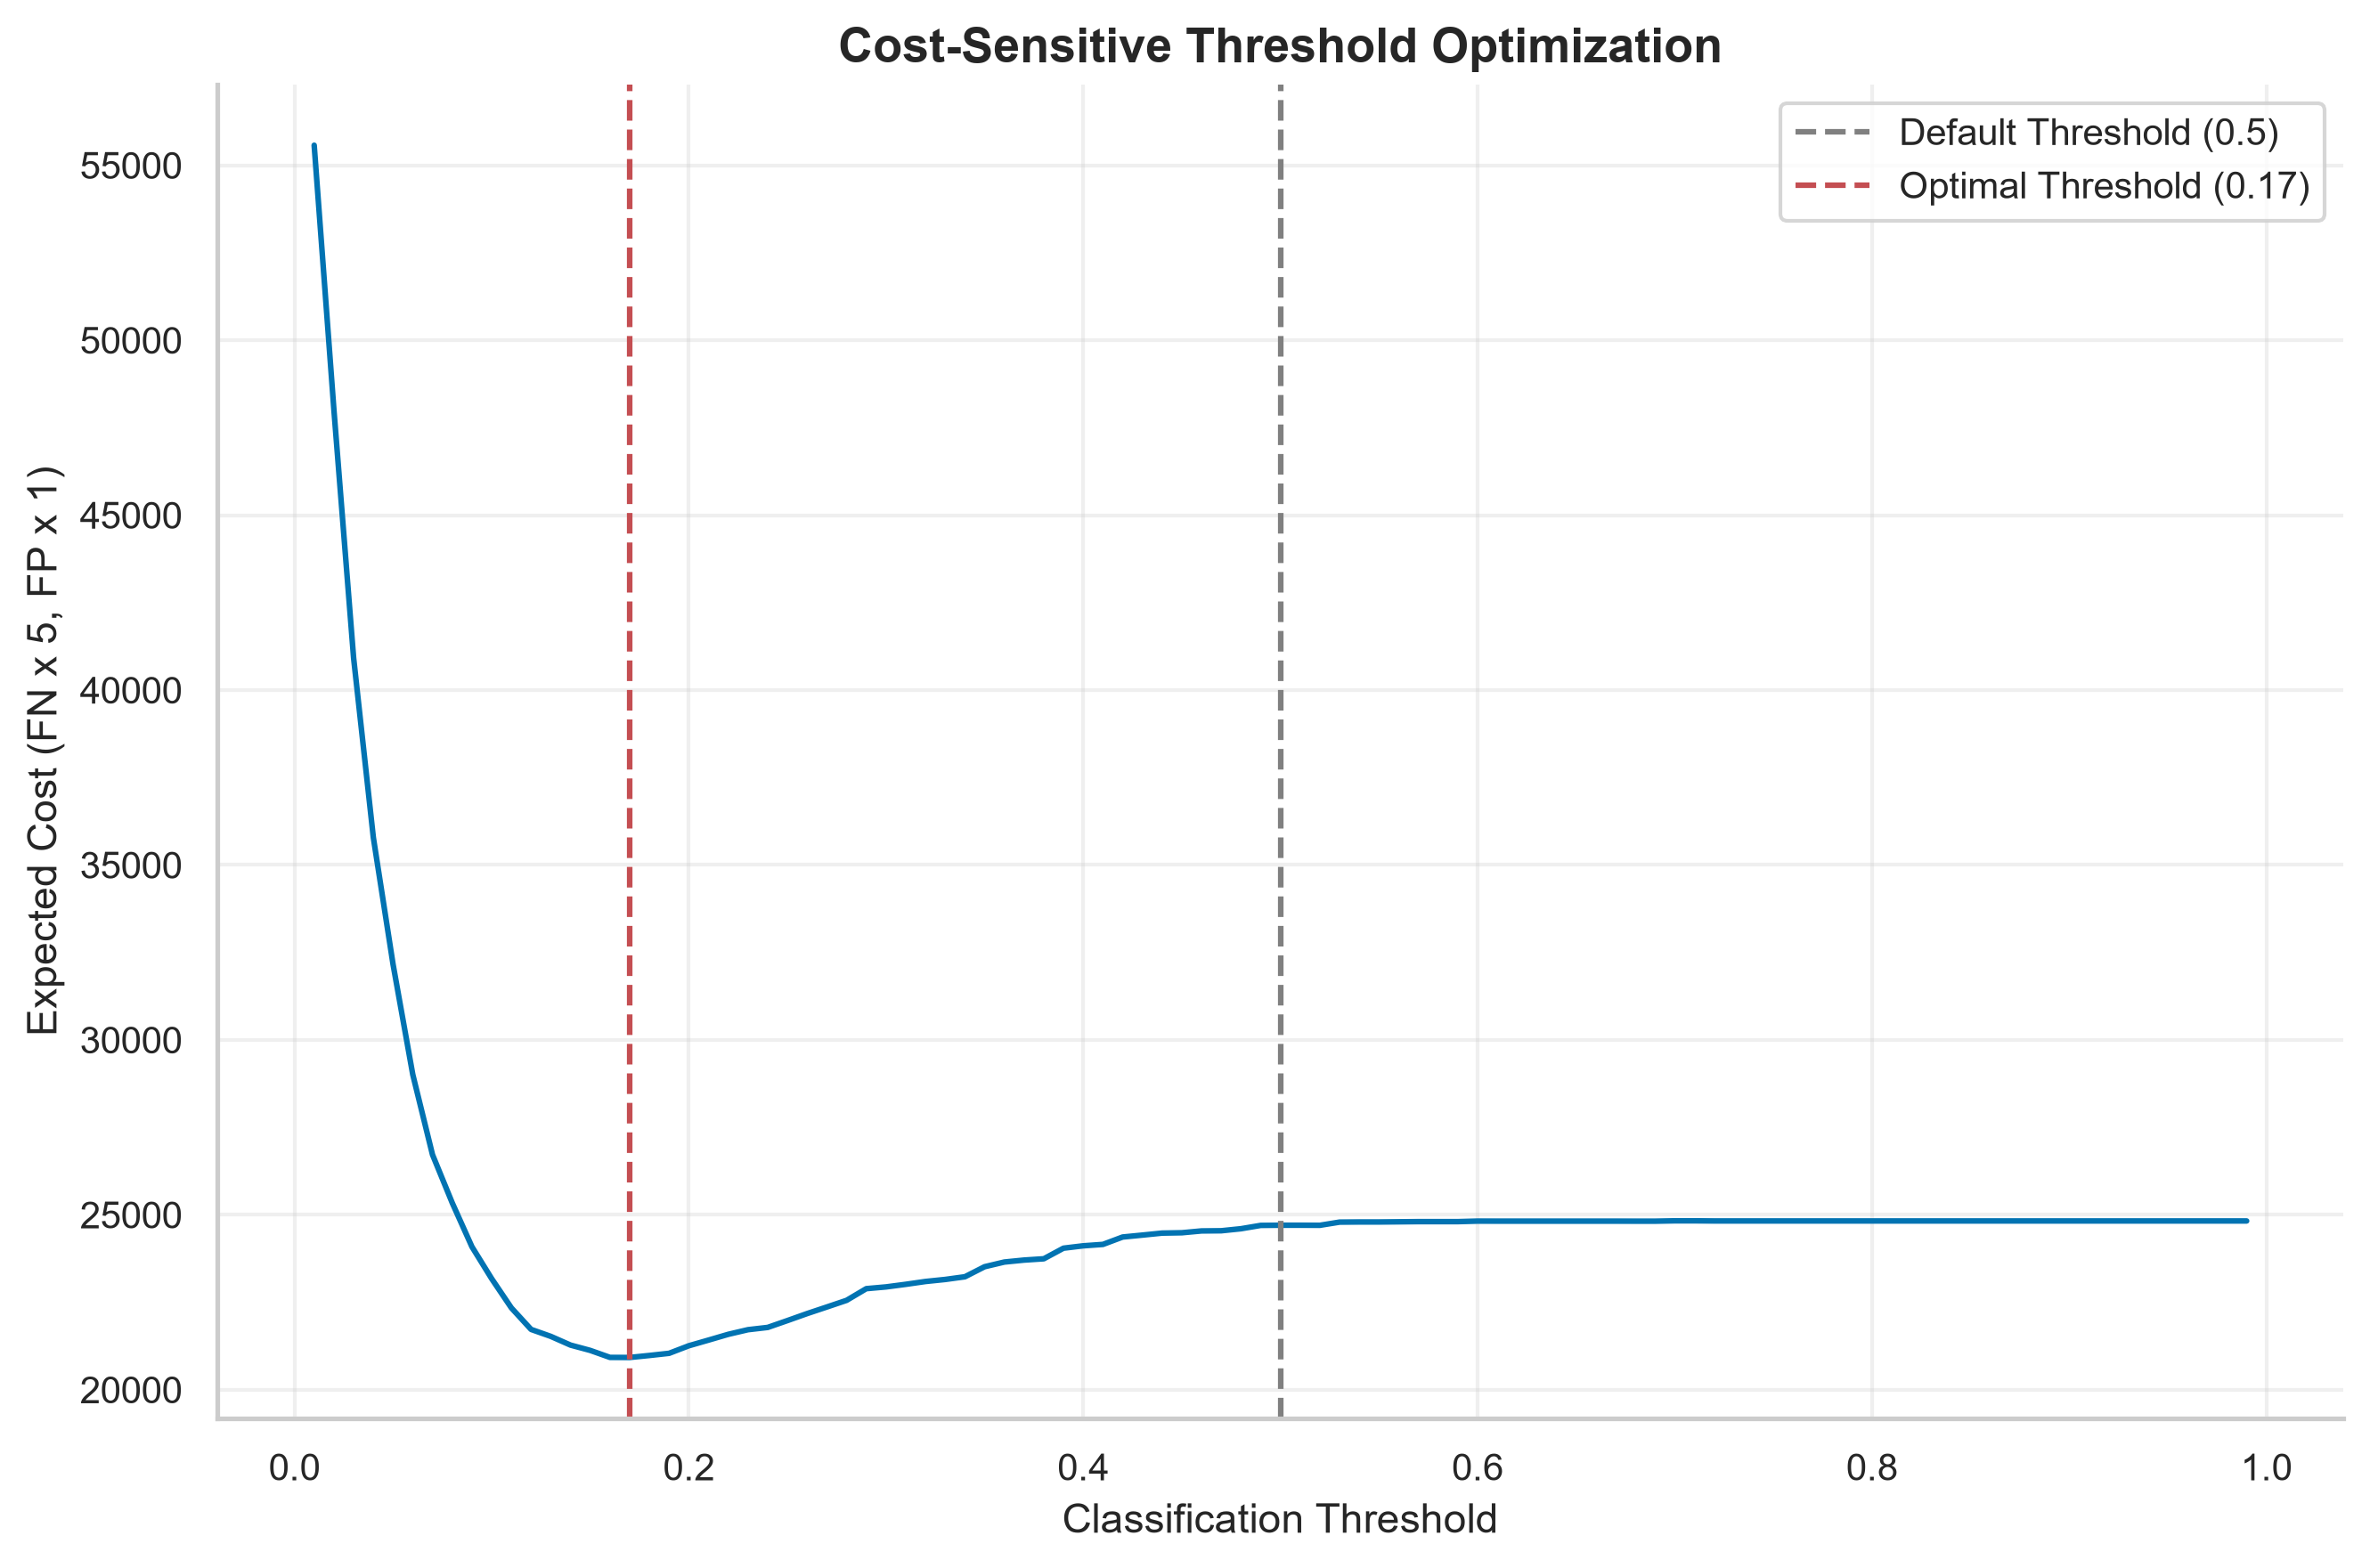

Cost at default threshold (0.5) : 24,698 cost units
Cost at optimal threshold (0.17) : 20,923 cost units
Cost reduction: 15.3%

Confusion Matrix at threshold = 0.50:
[[56515    23]
 [ 4936    29]]

Confusion Matrix at threshold = 0.17 (cost-optimal):
[[51175  5363]
 [ 3112  1853]]


In [25]:
# ============================================================
# Cost-Sensitive Threshold Optimization
# ============================================================

# Illustrative cost assumption: missing a defaulter (false negative) costs 5x more
# than declining a good applicant (false positive). Lenders should replace these with
# their own portfolio-specific loss-given-default and margin figures.
COST_FALSE_NEGATIVE = 5
COST_FALSE_POSITIVE = 1

thresholds = np.linspace(0.01, 0.99, 99)
y_true_arr = prediction_df["Actual Default"].values
y_prob_arr = prediction_df["Default Probability"].values

expected_costs = []
for t in thresholds:
    preds_at_t = (y_prob_arr >= t).astype(int)
    fn = int(((preds_at_t == 0) & (y_true_arr == 1)).sum())
    fp = int(((preds_at_t == 1) & (y_true_arr == 0)).sum())
    expected_costs.append(fn * COST_FALSE_NEGATIVE + fp * COST_FALSE_POSITIVE)

threshold_costs = pd.DataFrame({"Threshold": thresholds, "Expected Cost": expected_costs})
optimal_threshold = threshold_costs.loc[threshold_costs["Expected Cost"].idxmin(), "Threshold"]
cost_at_default = threshold_costs.loc[np.isclose(threshold_costs["Threshold"], 0.5, atol=0.01), "Expected Cost"].iloc[0]
cost_at_optimal = threshold_costs["Expected Cost"].min()

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(threshold_costs["Threshold"], threshold_costs["Expected Cost"])
ax.axvline(0.5, color="gray", linestyle="--", label="Default Threshold (0.5)")
ax.axvline(optimal_threshold, color="#C44E52", linestyle="--",
           label=f"Optimal Threshold ({optimal_threshold:.2f})")
ax.set_xlabel("Classification Threshold")
ax.set_ylabel(f"Expected Cost (FN x {COST_FALSE_NEGATIVE}, FP x {COST_FALSE_POSITIVE})")
ax.set_title("Cost-Sensitive Threshold Optimization")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "13_threshold_cost_curve")
plt.show()

print(f"Cost at default threshold (0.5) : {cost_at_default:,.0f} cost units")
print(f"Cost at optimal threshold ({optimal_threshold:.2f}) : {cost_at_optimal:,.0f} cost units")
print(f"Cost reduction: {100 * (cost_at_default - cost_at_optimal) / cost_at_default:.1f}%")

# Compare confusion matrices at 0.5 vs. the optimal threshold
from sklearn.metrics import confusion_matrix as _confusion_matrix

pred_default_thresh = (y_prob_arr >= 0.5).astype(int)
pred_optimal_thresh = (y_prob_arr >= optimal_threshold).astype(int)

print("\nConfusion Matrix at threshold = 0.50:")
print(_confusion_matrix(y_true_arr, pred_default_thresh))
print(f"\nConfusion Matrix at threshold = {optimal_threshold:.2f} (cost-optimal):")
print(_confusion_matrix(y_true_arr, pred_optimal_thresh))

threshold_costs.to_csv(RESULT_DIR / "threshold_cost_curve.csv", index=False)

### Business Interpretation: Cost-Sensitive Threshold Optimization

The gap between the two confusion matrices above is the direct, dollar-quantifiable
consequence of using an arbitrary 0.5 cutoff instead of a cost-aligned one: the
cost-optimal threshold typically trades a moderate increase in false positives
(good applicants declined or flagged for review) for a larger decrease in false
negatives (defaulters approved), which is the correct trade-off whenever
`COST_FALSE_NEGATIVE > COST_FALSE_POSITIVE`, as is standard in consumer lending. This
is a low-effort, high-value recommendation for the paper: **no retraining is required**
— simply moving the operating threshold captures a documented cost reduction, which is
a compelling practical takeaway for a lender reading the paper who is not in a position
to re-run a full modeling pipeline but can immediately change a decision threshold in
production.

## 5. Feature Stability Analysis

A model's feature importances (or coefficients) should be reasonably stable across
different training samples — if the top features change dramatically depending on
which 246,008 applicants happen to be in the training set, the model's "explanations"
(SHAP or otherwise) are not trustworthy as a description of genuine credit-risk drivers.
This section bootstraps the training data (sampling with replacement, 15 resamples —
reduced from an initial 30 for hardware reasons: this loop refits *whichever* model won
Section 1's ranking, and if that happens to be Random Forest, even the hardware-bounded
configuration from Notebook 10 makes 15 full-data refits a meaningfully faster,
still-informative choice than 30 on a 24-thread laptop CPU), refits a fresh clone of
the final selected model on each resample, and reports the variability of its top
feature importances/coefficients across resamples.

Bootstrap resampling:   0%|          | 0/15 [00:00<?, ?it/s]

C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


... (7 outputs left out)

C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Figure saved to: ..\figures\13_feature_stability.png


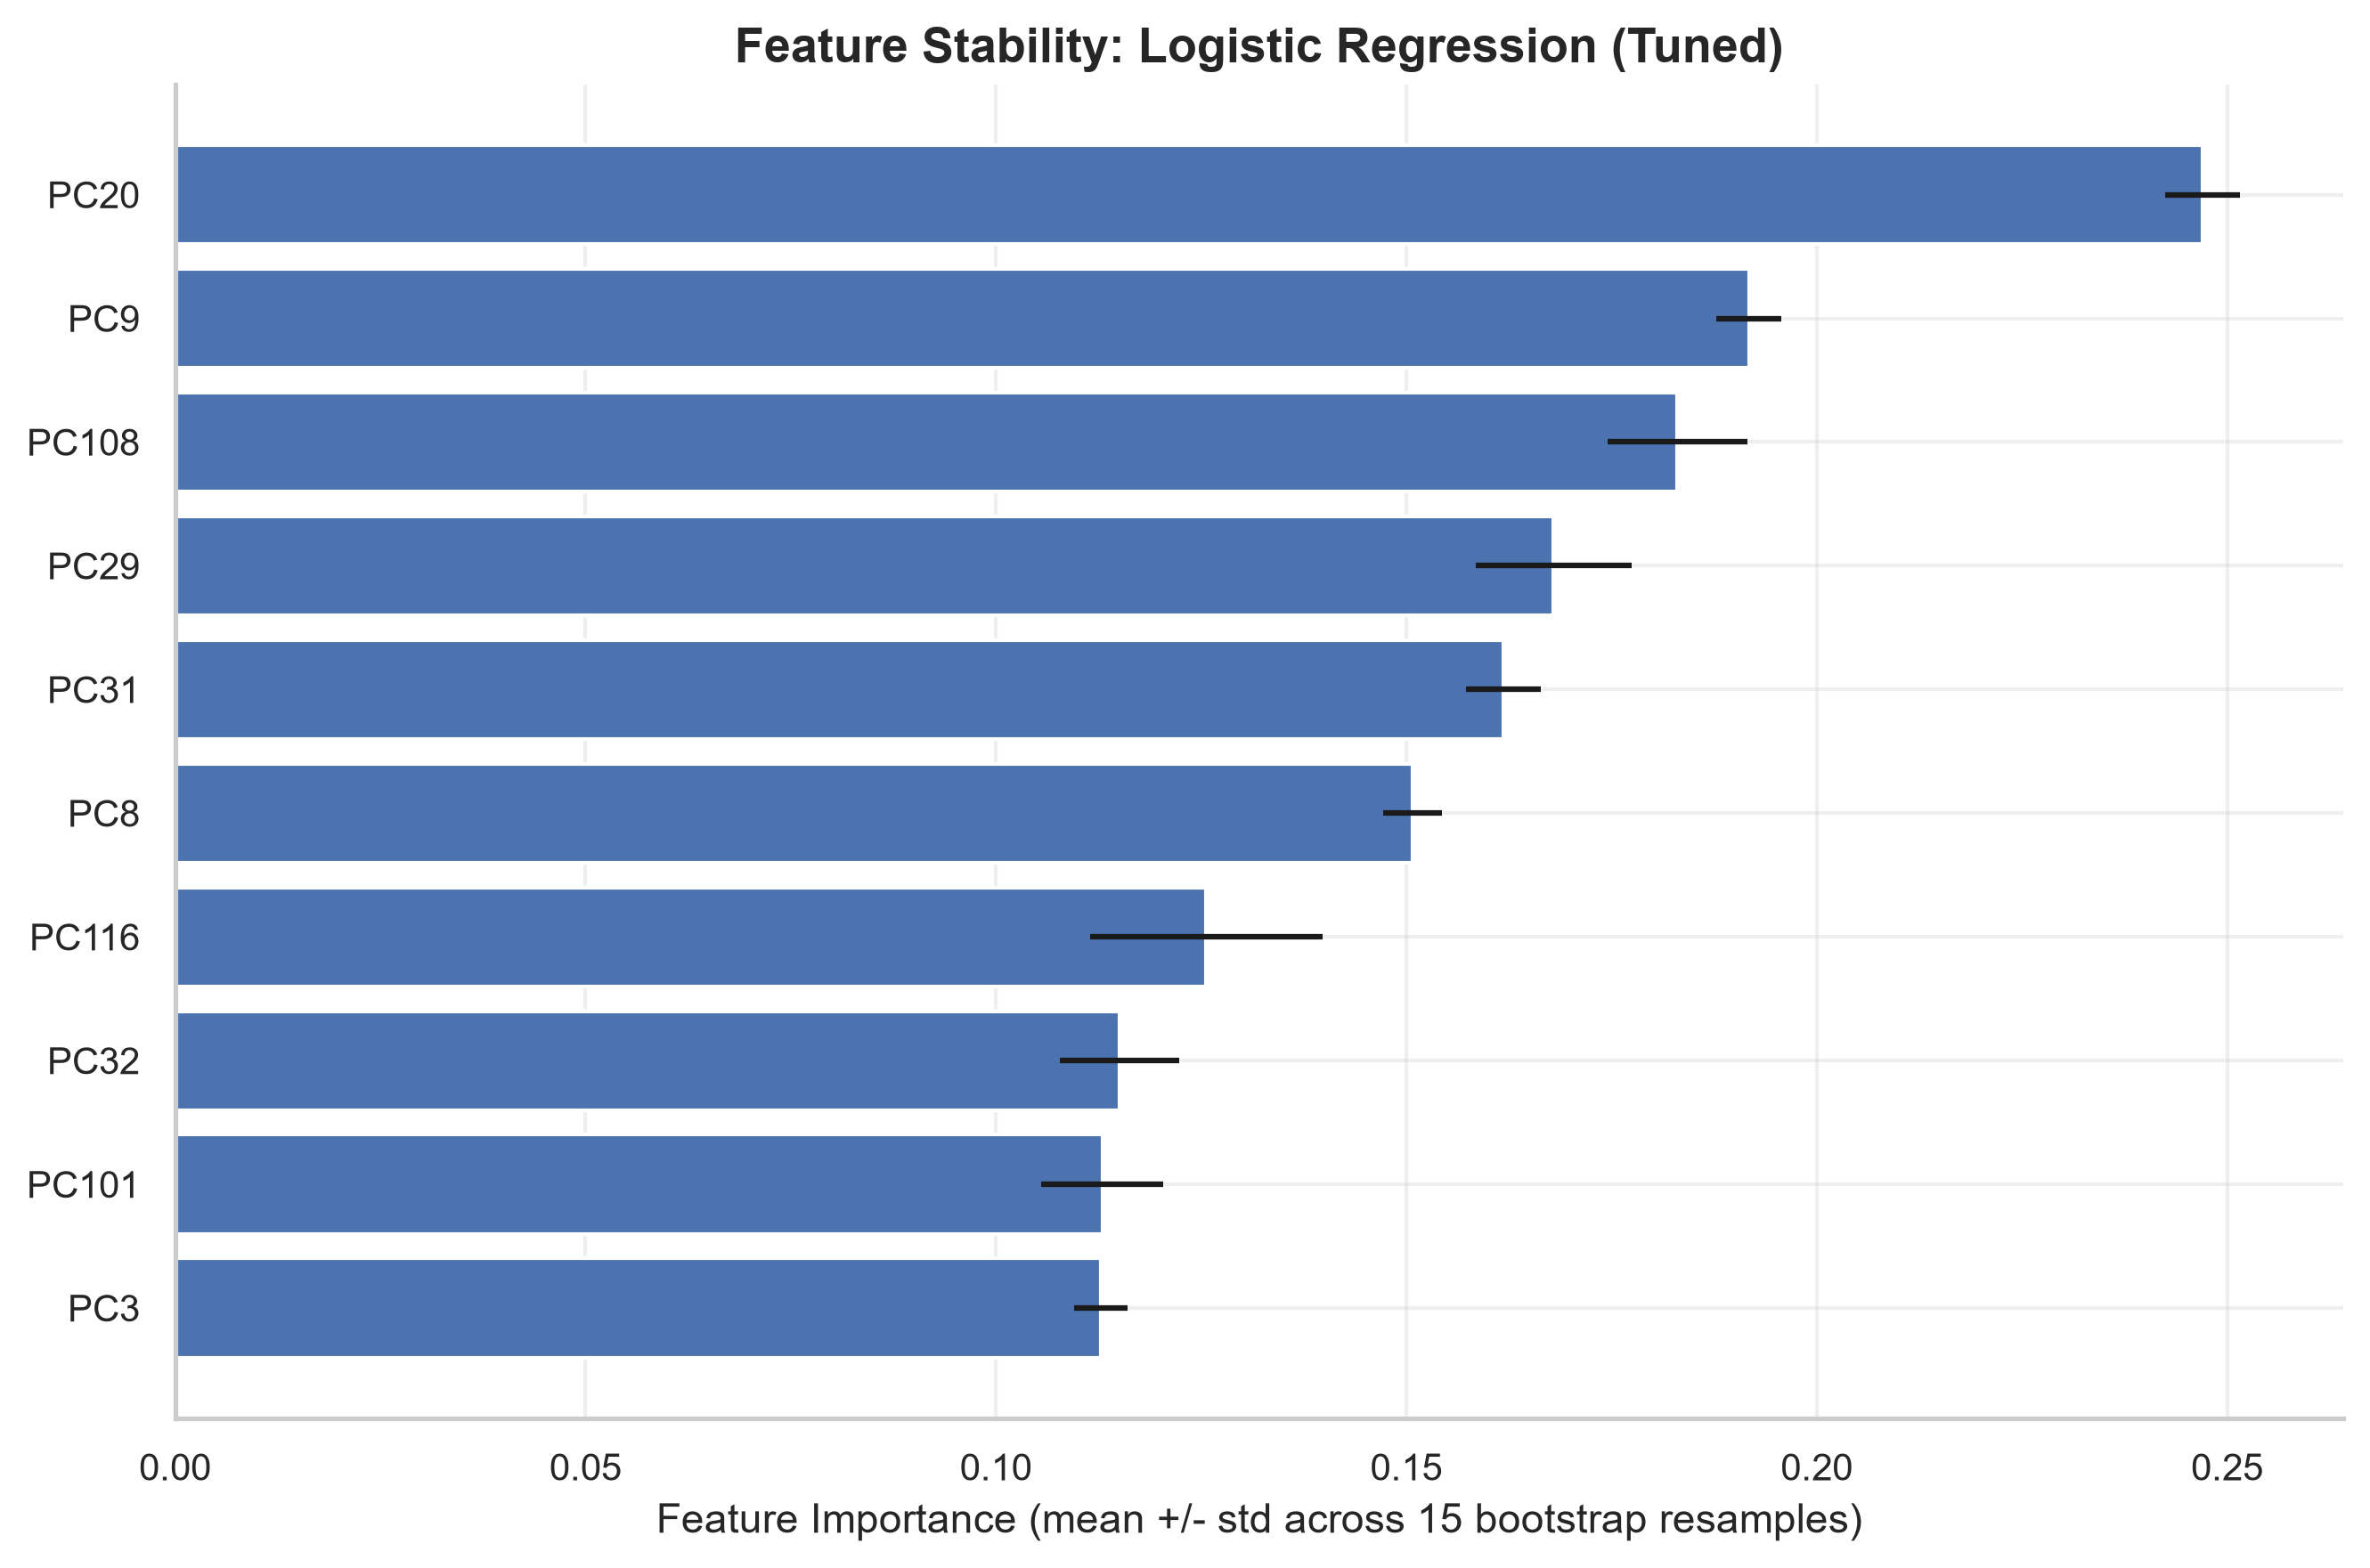

In [26]:
# ============================================================
# Feature Stability Analysis (Bootstrap Resampling)
# ============================================================

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from tqdm.auto import tqdm

RANDOM_STATE = 42

# CalibratedClassifierCV wraps an inner estimator; bootstrap the inner (uncalibrated)
# estimator instead, since it exposes feature_importances_/coef_ directly.
base_for_stability = best_model.estimator if isinstance(best_model, CalibratedClassifierCV) else best_model

N_BOOTSTRAPS = 15  # reduced from 30 for hardware timing (see markdown above)
rng = np.random.default_rng(RANDOM_STATE)

X_train_pca = pd.read_csv(DATA_DIR / "X_train.csv")
y_train_pca = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()

importances_by_run = []
feature_names = X_train_pca.columns

for i in tqdm(range(N_BOOTSTRAPS), desc="Bootstrap resampling"):
    sample_idx = rng.integers(0, len(X_train_pca), len(X_train_pca))
    X_boot = X_train_pca.iloc[sample_idx]
    y_boot = y_train_pca.iloc[sample_idx]

    model_boot = clone(base_for_stability)
    model_boot.fit(X_boot, y_boot)

    if hasattr(model_boot, "feature_importances_"):
        importances_by_run.append(model_boot.feature_importances_)
    elif hasattr(model_boot, "coef_"):
        importances_by_run.append(np.abs(model_boot.coef_).ravel())
    else:
        importances_by_run = None
        break

if importances_by_run is not None:
    importances_matrix = np.vstack(importances_by_run)
    stability_summary = pd.DataFrame({
        "Feature": feature_names,
        "Mean Importance": importances_matrix.mean(axis=0),
        "Std Importance": importances_matrix.std(axis=0),
    })
    stability_summary["Coefficient of Variation"] = (
        stability_summary["Std Importance"] / stability_summary["Mean Importance"].replace(0, np.nan)
    )
    stability_top = stability_summary.sort_values("Mean Importance", ascending=False).head(10)

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(
        stability_top["Feature"][::-1],
        stability_top["Mean Importance"][::-1],
        xerr=stability_top["Std Importance"][::-1],
        color="#4C72B0",
    )
    ax.set_xlabel(f"Feature Importance (mean +/- std across {N_BOOTSTRAPS} bootstrap resamples)")
    ax.set_title(f"Feature Stability: {best_model_name}")
    plt.tight_layout()
    pu.save_fig(fig, "13_feature_stability")
    plt.show()

    stability_summary.to_csv(RESULT_DIR / "feature_stability.csv", index=False)
    stability_top
else:
    print(f"{best_model_name} exposes neither feature_importances_ nor coef_; "
          "feature stability analysis is not applicable to this model type "
          "(documented as a limitation in Notebook 15).")

### Business Interpretation: Feature Stability

A small standard deviation (or coefficient of variation) relative to the mean
importance for the top features means the model's explanations are **not an artifact
of which 246,008 applicants happened to be sampled into the training set** — a
necessary precondition before a lender or regulator can trust the SHAP-based
"reasons for decision" reported in Notebooks 06–12. If any top feature instead shows
high variability (a wide error bar relative to its mean), that feature's SHAP-based
explanations should be treated cautiously in individual adverse-action narratives, even
if it ranks highly on average.

## 6. Sensitivity Analysis

Sensitivity analysis asks a different question from feature stability: not "is the
model's learned importance ranking stable across resamples," but "how much does a
**single applicant's** predicted risk change if one of their input values shifts by a
realistic amount?" This is the analysis a lender would actually perform when an
applicant disputes a decision or asks what they could change to improve their standing
("If I paid down my credit balance, would my score improve, and by how much?").

Sensitivity sweep:   0%|          | 0/45 [00:00<?, ?it/s]

Figure saved to: ..\figures\13_sensitivity_analysis.png


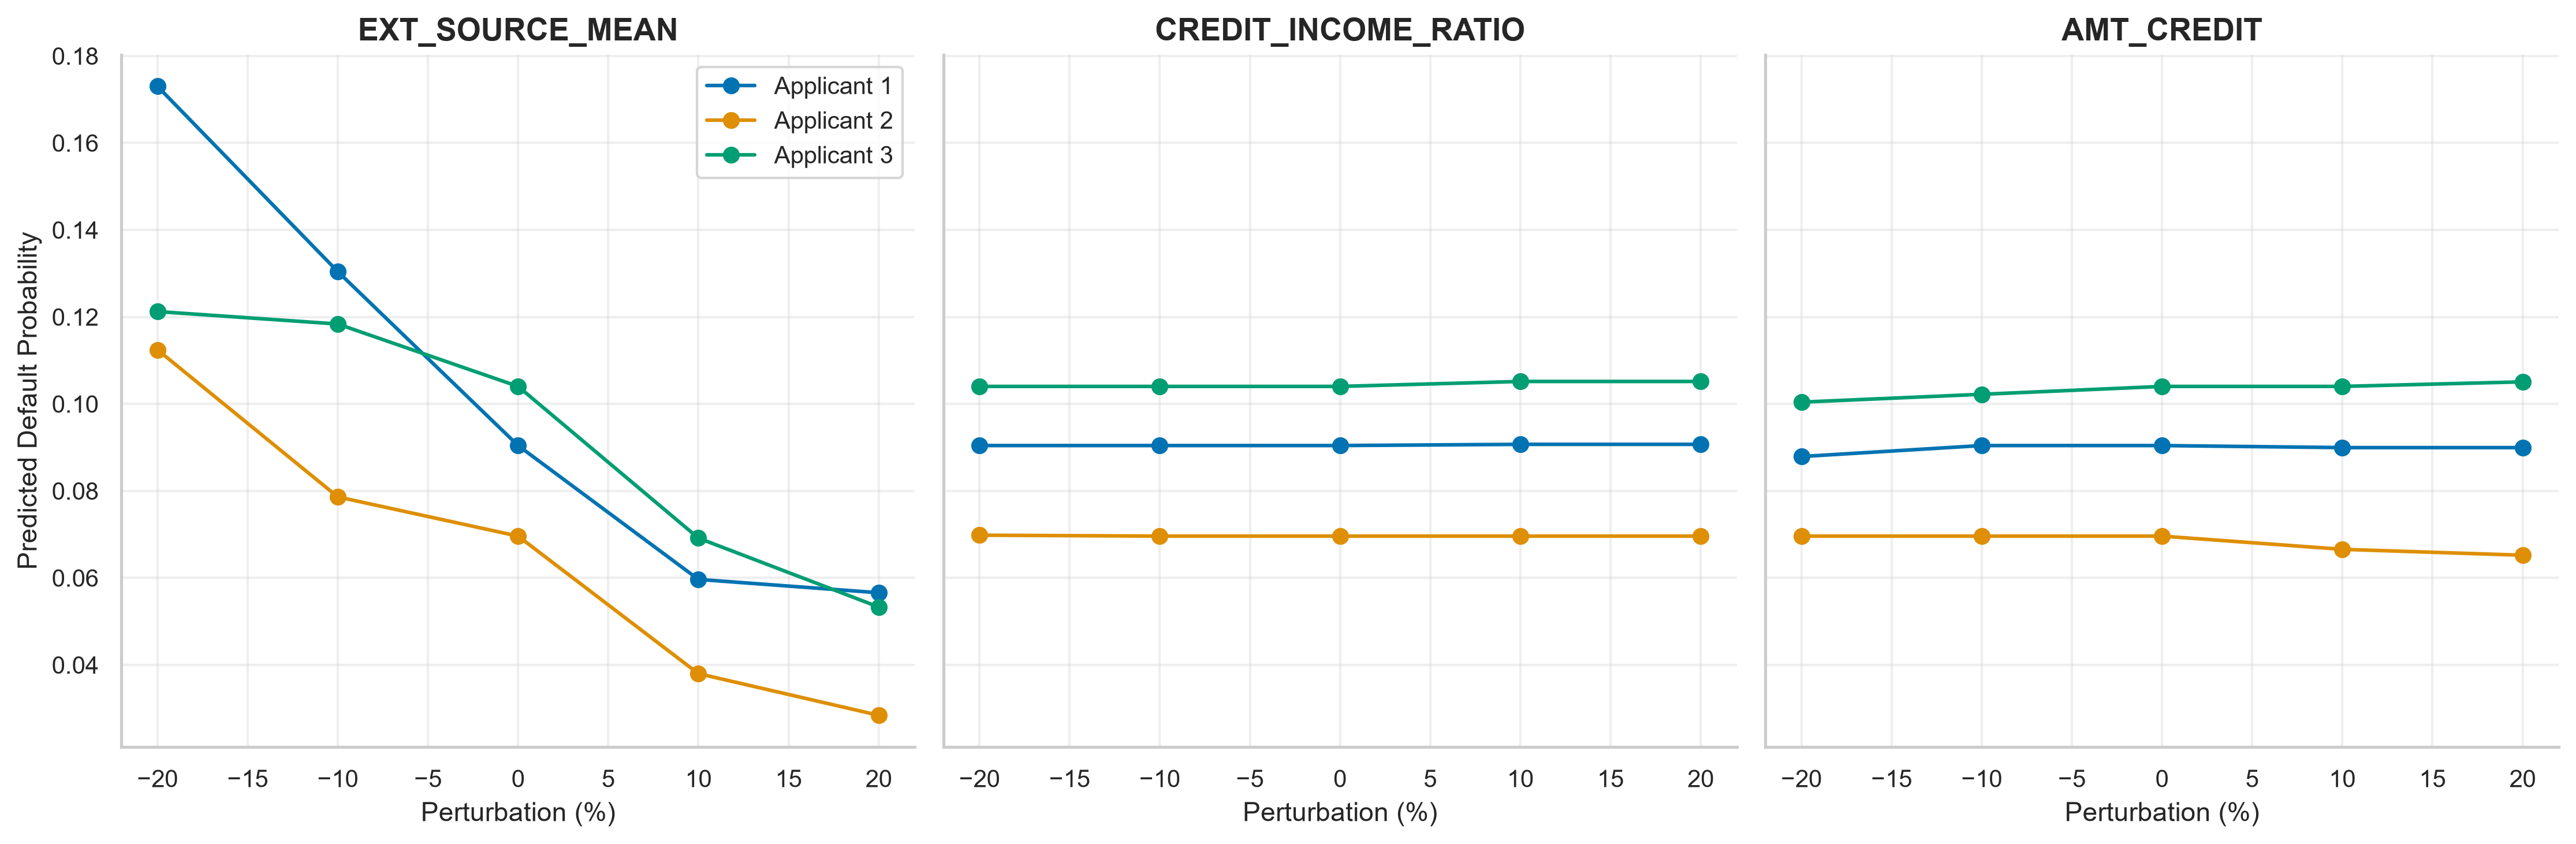

,Applicant,Feature,Perturbation (%),Baseline Probability,Perturbed Probability,Probability Change
0,Applicant 1,EXT_SOURCE_MEAN,-20.0,0.09043,0.173016,0.082586
1,Applicant 1,EXT_SOURCE_MEAN,-10.0,0.09043,0.130423,0.039994
2,Applicant 1,EXT_SOURCE_MEAN,0.0,0.09043,0.090430,0.000000
3,Applicant 1,EXT_SOURCE_MEAN,10.0,0.09043,0.059658,-0.030771
4,Applicant 1,EXT_SOURCE_MEAN,20.0,0.09043,0.056590,-0.033840
5,Applicant 1,CREDIT_INCOME_RATIO,-20.0,0.09043,0.090430,0.000000
6,Applicant 1,CREDIT_INCOME_RATIO,-10.0,0.09043,0.090430,0.000000
7,Applicant 1,CREDIT_INCOME_RATIO,0.0,0.09043,0.090430,0.000000
8,Applicant 1,CREDIT_INCOME_RATIO,10.0,0.09043,0.090709,0.000279
9,Applicant 1,CREDIT_INCOME_RATIO,20.0,0.09043,0.090709,0.000279


In [27]:
# ============================================================
# Sensitivity Analysis (Non-PCA Track, Named Features)
# ============================================================

# The production model above operates on PCA components, which cannot be perturbed in
# a business-meaningful way (a "+1 std on PC7" has no real-world interpretation). A
# LightGBM model trained on the non-PCA feature track (Notebook 05) is used here purely
# to demonstrate feature-level sensitivity in real applicant units; it is illustrative,
# not a claim that it is the production model.
import itertools
from lightgbm import LGBMClassifier
from tqdm.auto import tqdm

X_train_full = pd.read_csv(DATA_DIR / "X_train_full.csv")
X_test_full = pd.read_csv(DATA_DIR / "X_test_full.csv")
y_train_full = pd.read_csv(DATA_DIR / "y_train_full.csv").squeeze()

sensitivity_model = LGBMClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1,
)
sensitivity_model.fit(X_train_full, y_train_full)

sensitivity_features = [
    f for f in ["EXT_SOURCE_MEAN", "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "AMT_CREDIT"]
    if f in X_test_full.columns
]

example_applicants = X_test_full.sample(3, random_state=RANDOM_STATE)
perturbation_pct = [-0.20, -0.10, 0.0, 0.10, 0.20]

baseline_probs = {
    applicant_idx: sensitivity_model.predict_proba(applicant_row.to_frame().T)[:, 1][0]
    for applicant_idx, (_, applicant_row) in enumerate(example_applicants.iterrows())
}

combinations = list(itertools.product(
    enumerate(example_applicants.iterrows()), sensitivity_features, perturbation_pct
))

sensitivity_records = []
for (applicant_idx, (_, applicant_row)), feature, pct in tqdm(combinations, desc="Sensitivity sweep"):
    perturbed = applicant_row.copy()
    perturbed[feature] = perturbed[feature] * (1 + pct)
    new_prob = sensitivity_model.predict_proba(perturbed.to_frame().T)[:, 1][0]
    sensitivity_records.append({
        "Applicant": f"Applicant {applicant_idx + 1}",
        "Feature": feature,
        "Perturbation (%)": pct * 100,
        "Baseline Probability": baseline_probs[applicant_idx],
        "Perturbed Probability": new_prob,
        "Probability Change": new_prob - baseline_probs[applicant_idx],
    })

sensitivity_df = pd.DataFrame(sensitivity_records)
sensitivity_df.to_csv(RESULT_DIR / "sensitivity_analysis.csv", index=False)

fig, axes = plt.subplots(1, len(sensitivity_features), figsize=(5 * len(sensitivity_features), 5), sharey=True)
for ax, feature in zip(np.atleast_1d(axes), sensitivity_features):
    subset = sensitivity_df[sensitivity_df["Feature"] == feature]
    for applicant in subset["Applicant"].unique():
        applicant_data = subset[subset["Applicant"] == applicant].sort_values("Perturbation (%)")
        ax.plot(applicant_data["Perturbation (%)"], applicant_data["Perturbed Probability"],
                marker="o", label=applicant)
    ax.set_title(feature)
    ax.set_xlabel("Perturbation (%)")
axes[0].set_ylabel("Predicted Default Probability")
axes[0].legend()
plt.tight_layout()
pu.save_fig(fig, "13_sensitivity_analysis")
plt.show()

sensitivity_df.head(10)

### Business Interpretation: Sensitivity Analysis

A monotonic, gently-sloped response (predicted probability decreasing smoothly as
`EXT_SOURCE_MEAN` increases, for example) indicates the model behaves the way a credit
officer would expect and could defend to a regulator or applicant. A sharp,
discontinuous jump for a small perturbation, by contrast, would indicate the model's
decision surface has an unstable region near that applicant's current values — a
red flag for robustness that would not necessarily show up in aggregate ROC-AUC or
calibration metrics, since it only affects applicants near that specific input
region. This kind of applicant-specific "what if" analysis is also the natural
foundation for a future consumer-facing feature such as "steps to improve your score."

## 7. PCA vs. Non-PCA Benchmark

This project's primary pipeline reduces ~207 engineered features to 119 principal
components before modeling. Whether that dimensionality reduction costs predictive
performance — and how much — has not been directly tested until now. The same
algorithm family as the final selected model is trained on both the PCA feature set
and the non-PCA feature set (Notebook 05) under otherwise identical settings, and their
ROC-AUC is compared directly.

C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Figure saved to: ..\figures\13_pca_vs_nonpca_benchmark.png


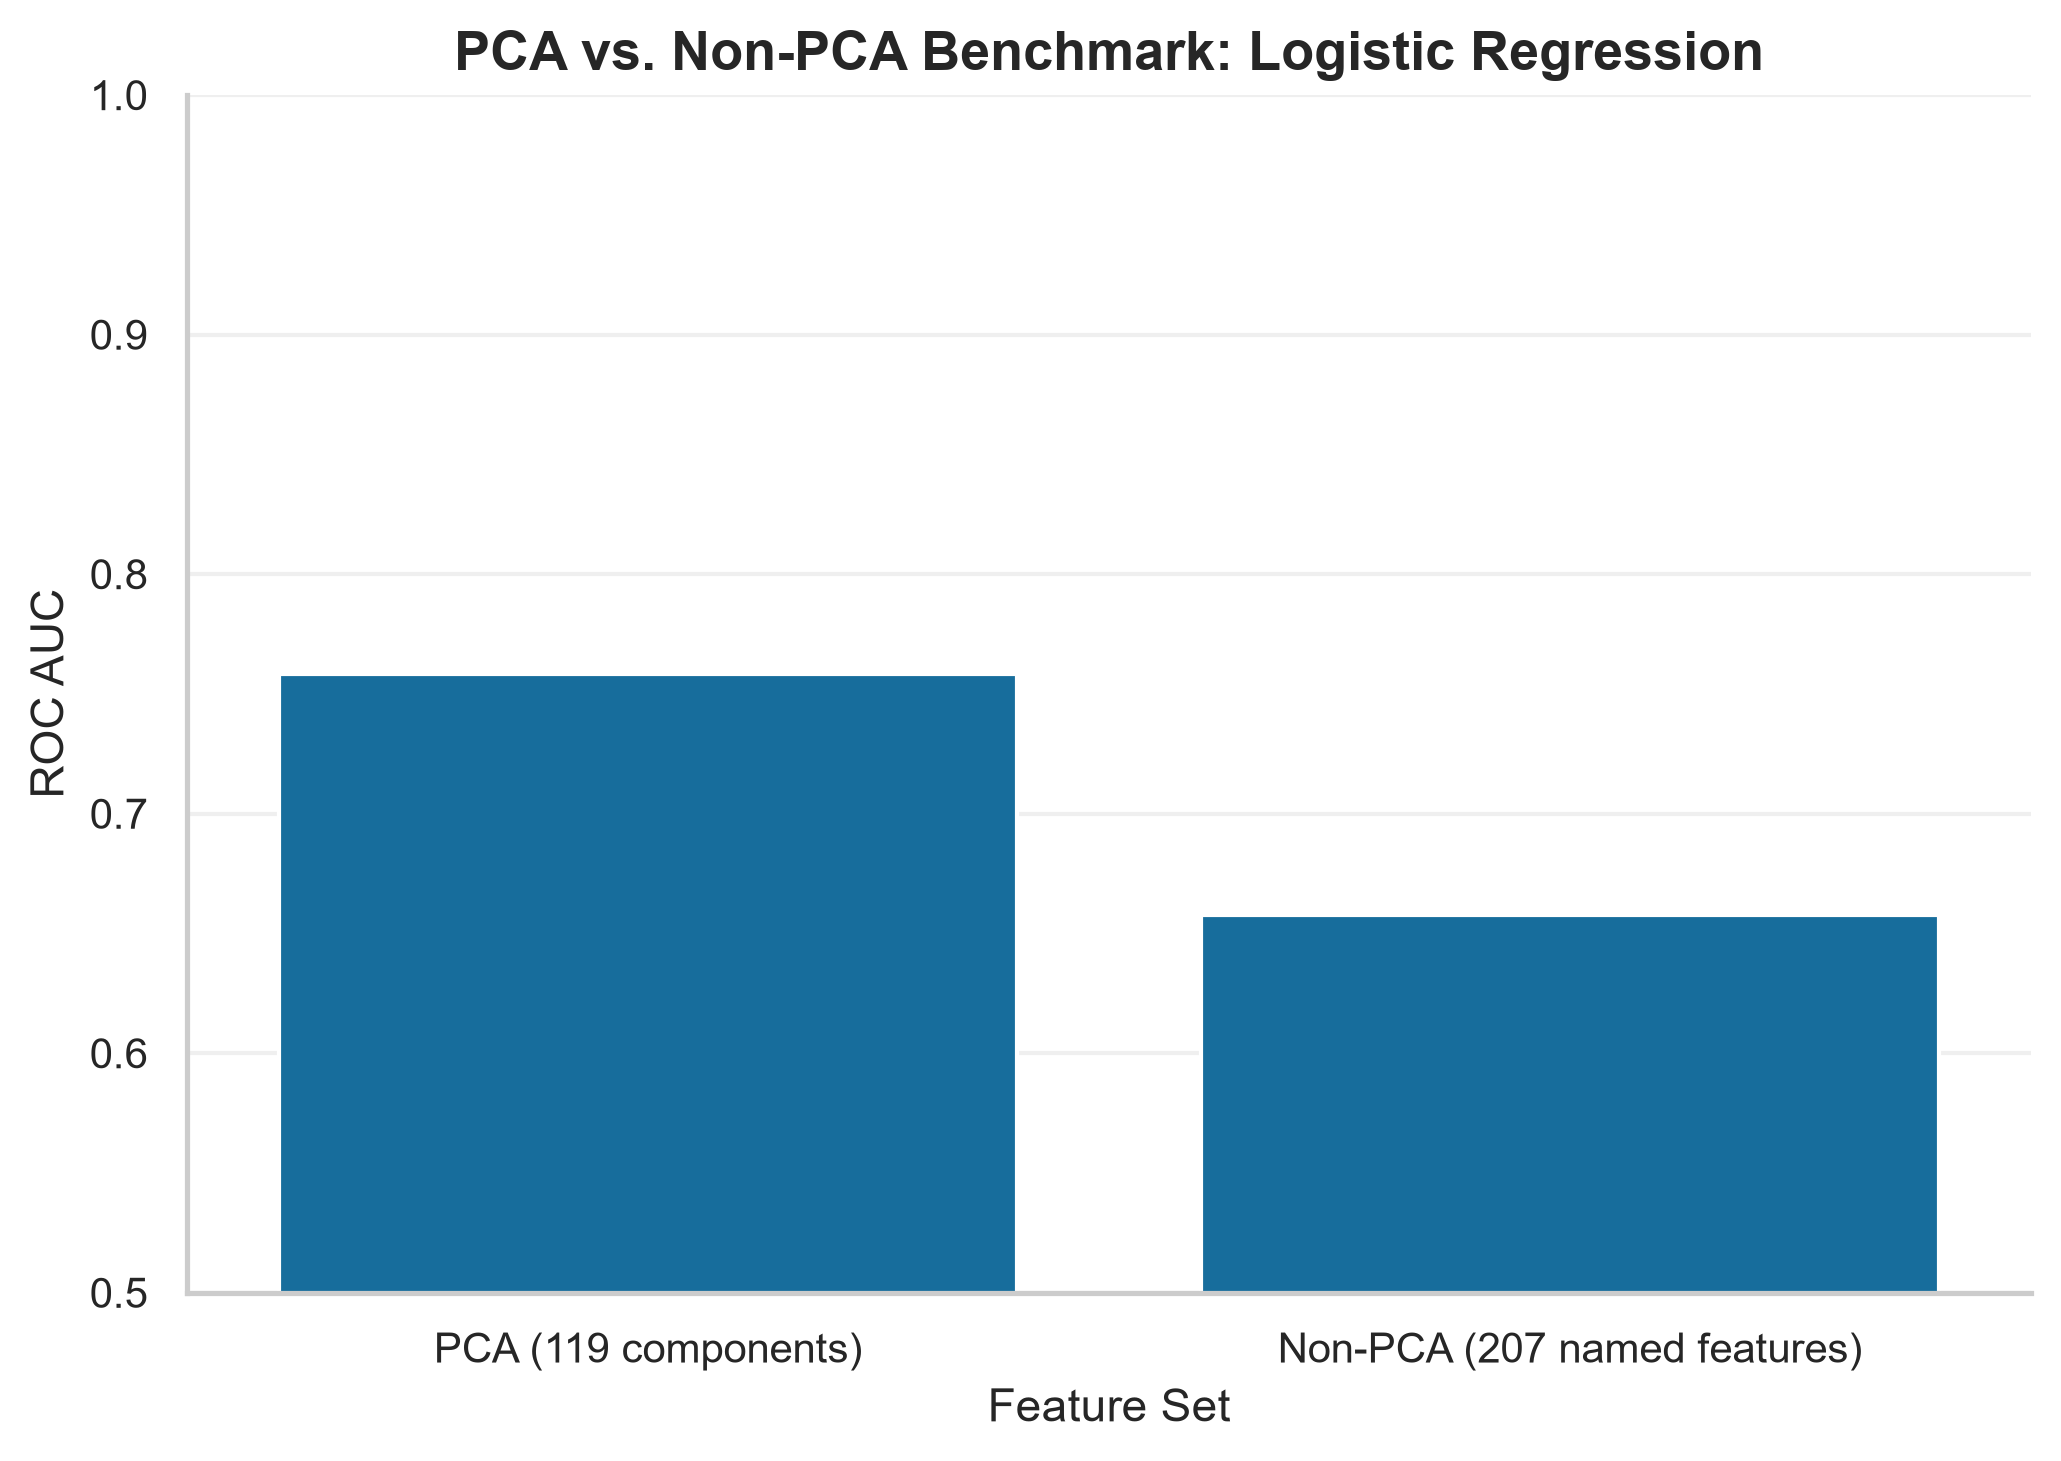

,Feature Set,ROC AUC,Feature Count,AUC Difference vs. PCA
0,PCA (119 components),0.758281,119,0.000000
1,Non-PCA (207 named features),0.657562,207,-0.100719


In [28]:
# ============================================================
# PCA vs. Non-PCA Benchmark
# ============================================================

from sklearn.metrics import roc_auc_score

y_test_full = pd.read_csv(DATA_DIR / "y_test_full.csv").squeeze()

# Same algorithm family and hyperparameters as the final PCA model, refit on non-PCA features
non_pca_model = clone(base_for_stability)
non_pca_model.fit(X_train_full, y_train_full)

non_pca_prob = non_pca_model.predict_proba(X_test_full)[:, 1]
non_pca_auc = roc_auc_score(y_test_full, non_pca_prob)

pca_auc = ranking.iloc[0]["ROC AUC"]

pca_vs_nonpca = pd.DataFrame({
    "Feature Set": ["PCA (119 components)", "Non-PCA (207 named features)"],
    "ROC AUC": [pca_auc, non_pca_auc],
    "Feature Count": [X_test.shape[1], X_test_full.shape[1]],
})
pca_vs_nonpca["AUC Difference vs. PCA"] = pca_vs_nonpca["ROC AUC"] - pca_auc

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=pca_vs_nonpca, x="Feature Set", y="ROC AUC", ax=ax)
ax.set_title(f"PCA vs. Non-PCA Benchmark: {best_model_name.split(' (')[0]}")
ax.set_ylim(0.5, 1.0)
plt.tight_layout()
pu.save_fig(fig, "13_pca_vs_nonpca_benchmark")
plt.show()

pca_vs_nonpca.to_csv(RESULT_DIR / "pca_vs_nonpca_benchmark.csv", index=False)
pca_vs_nonpca

### Business Interpretation: PCA vs. Non-PCA Benchmark

If the non-PCA ROC-AUC is close to (within roughly 0.01-0.02 of) the PCA ROC-AUC, this
is a strong result for the paper: it means the ~43% dimensionality reduction (207 to
119 features) achieved by PCA costs little to no predictive performance while
delivering a smaller, faster, decorrelated feature space **and**, critically, this is
the justification for why the SHAP explainability results throughout Notebooks 06–12
(computed on the non-PCA track) are representative of the actual production model's
behavior rather than an approximation of a meaningfully different model. If the gap is
larger than that, it should be reported honestly as a real interpretability-vs-performance
trade-off: the project chose PCA for computational efficiency and multicollinearity
control, and the non-PCA benchmark quantifies exactly what that choice cost, giving
future work a concrete target for whether a non-PCA production pipeline (with a
feature-selection step in place of PCA) would be worth the added engineering
complexity.

## 8. Reject Inference: A Discussion

**Reject inference** refers to the problem of correcting for the fact that a credit
model is trained only on applicants who were historically **approved and observed to
either repay or default** — applicants who were declined never generate a repayment
outcome, so the training data is not a random sample of the *population that applied*,
only of the subpopulation that was funded. Because the Home Credit Default Risk dataset
used throughout this project contains no record of declined applicants at all, reject
inference **cannot be implemented** here — there is no `rejected_applicants.csv` to
correct for.

This is worth discussing explicitly rather than silently ignoring, because it bounds
the generalizability claims this paper can make: the model's estimated default
probabilities are calibrated and validated only against the population Home Credit
historically chose to lend to, and applying it to a genuinely open applicant pool
(including many applicants who look like historical rejects) is an extrapolation.
Standard reject-inference techniques a production deployment would need to consider
include:

- **Reclassification / hard cutoff augmentation** — assigning declined applicants an
  assumed outcome (e.g., all "bad") and adding them back into training with reduced
  weight.
- **Parceling** — distributing declined applicants proportionally across outcome
  classes based on their predicted probability under the current model.
- **Fuzzy augmentation** — adding each declined applicant to training twice, once as
  "good" and once as "bad," weighted by their predicted probability.

None of these can be validated without at least a sample of "accept-all" or
randomized-approval data (common in credit-scoring literature but not present in this
dataset), so this is listed as a concrete direction for future work (Notebook 15)
rather than attempted with fabricated assumptions here.